# Consolidated exploratory diagnostics — PA43

This notebook collects the essential warm-up, calendar-feature and rain-transition
investigations in one place. It uses **only the 30 shared saved prediction
histories** under `results/final/predictions/`; it does not train models.
The required A/B results are presented separately in `final_results.ipynb`.

The diagnostic comparisons below investigate sensitivity and error structure.
The comparisons describe observed differences without establishing statistical
significance or the causes of temporal variation.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "stream_analysis.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.stream_analysis import (
    SEED, FEATURES, CANDIDATES, CITIES, GROUPS, SCORES, TRANSITIONS,
    FINAL_START, COMMON_START, END, model_factories, package_versions,
    generate_predictions, load_predictions, refresh_results,
)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)
MODELS = list(model_factories())
SHORT = ["GNB", "LogReg", "HT", "Bagging", "ARF"]
COLORS = dict(zip(MODELS, plt.get_cmap("tab10").colors))

In [2]:
predictions = load_predictions()
tables = refresh_results(predictions)
OUTPUT = ROOT / "results" / "exploratory"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
display(pd.Series(package_versions(), name="version").to_frame())
print("Seed:", SEED, "| Shared histories:", predictions.groupby(GROUPS).ngroups)

,version
python,3.13.7
river,0.26.1
pandas,3.0.6
numpy,2.5.4
scipy,1.18.1
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


Seed: 42 | Shared histories: 30


In [3]:
def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def show_scores(table, extra=()):
    columns = GROUPS + list(extra) + ["n_events", "rain_hours", "dry_hours"] + SCORES
    displayed = table[columns].copy()
    numeric = displayed.select_dtypes(include="number").columns
    displayed[numeric] = displayed[numeric].round(4)
    display(displayed)

## 1. Warm-up sensitivity: scoring intervals versus learning history

Warm-up excludes early predictions from **scoring**, while the model keeps
learning at every eligible hour. A larger value does not increase a moving
training window: learned model state can retain information from the entire
preceding stream. The 6/24-hour B windows describe input features, not a limit
on what the model has learned.

Both representations start on January 2 after 24 hours needed for past-only
features. Boundaries of 30/90/180 days count from **January 1, 2021**; the annual
boundary is January 1, 2022. Each candidate below therefore evaluates a different
historical interval. Differences cannot be attributed only to initial training.
The final protocol adopts 30 days; that choice is not a statistical optimum.

,warmup,boundary,evaluation_start,evaluation_end,n_events,learning_hours_before_scoring
0,0 days,2021-01-02 00:00:00+00:00,2021-01-02 00:00:00+00:00,2025-12-31 23:00:00+00:00,43800,0
1,30 days,2021-01-31 00:00:00+00:00,2021-01-31 00:00:00+00:00,2025-12-31 23:00:00+00:00,43104,696
2,90 days,2021-04-01 00:00:00+00:00,2021-04-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,41664,2136
3,180 days,2021-06-30 00:00:00+00:00,2021-06-30 00:00:00+00:00,2025-12-31 23:00:00+00:00,39504,4296
4,Calendar year 2021,2022-01-01 00:00:00+00:00,2022-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,35064,8736


,city,representation,model,warmup,rain_hours,dry_hours,accuracy,macro_f1,precision,recall
0,Faro,A,GaussianNB,0 days,3876,39924,0.9449,0.7840,0.8445,0.4623
1,Faro,A,GaussianNB,30 days,3802,39302,0.9454,0.7846,0.8515,0.4613
2,Faro,A,GaussianNB,90 days,3593,38071,0.9465,0.7848,0.8490,0.4617
3,Faro,A,GaussianNB,180 days,3380,36124,0.9478,0.7901,0.8502,0.4734
4,Faro,A,GaussianNB,Calendar year 2021,3133,31931,0.9456,0.7897,0.8509,0.4737
5,Faro,A,LogisticRegression,0 days,3876,39924,0.9519,0.8506,0.7292,0.7260
6,Faro,A,LogisticRegression,30 days,3802,39302,0.9521,0.8509,0.7295,0.7265
7,Faro,A,LogisticRegression,90 days,3593,38071,0.9525,0.8490,0.7253,0.7225
8,Faro,A,LogisticRegression,180 days,3380,36124,0.9526,0.8484,0.7242,0.7210
9,Faro,A,LogisticRegression,Calendar year 2021,3133,31931,0.9499,0.8458,0.7207,0.7175


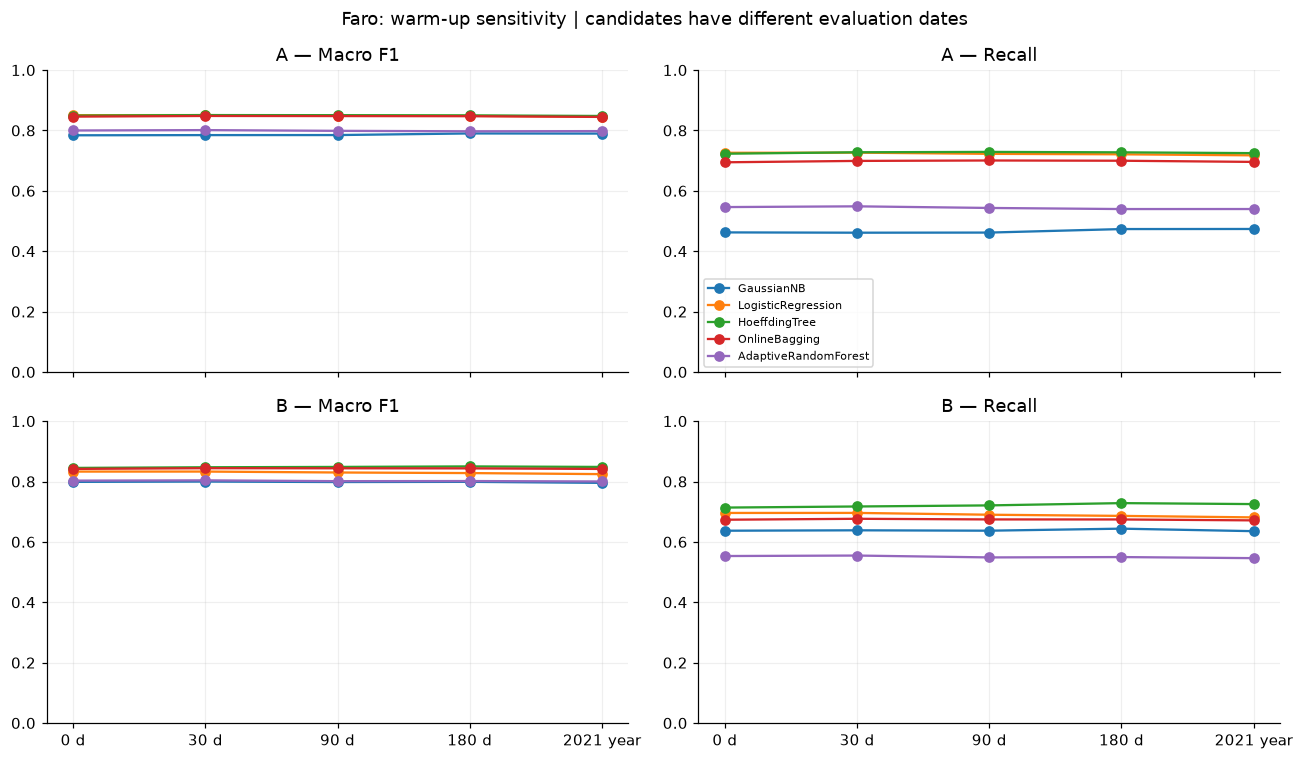

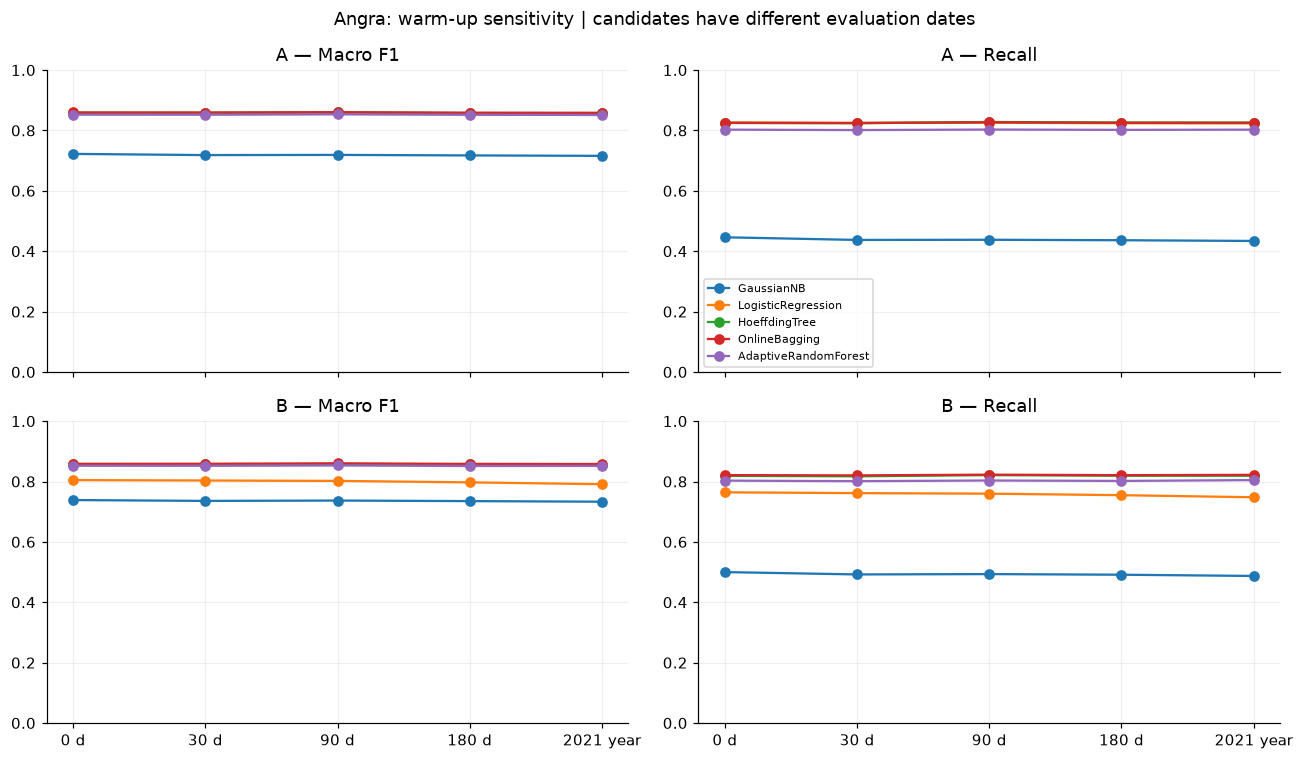

In [4]:
warmup = tables["warmup_metrics"]
support_columns = ["warmup", "boundary", "evaluation_start", "evaluation_end", "n_events", "learning_hours_before_scoring"]
display(warmup[support_columns].drop_duplicates().reset_index(drop=True))
display(warmup[GROUPS + ["warmup", "rain_hours", "dry_hours"] + SCORES].round(4))
for city in CITIES:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    for row, rep in enumerate(["A", "B"]):
        for col, metric in enumerate(["macro_f1", "recall"]):
            ax = axes[row, col]
            for name in MODELS:
                part = warmup.query("city == @city and representation == @rep and model == @name").set_index("warmup").reindex(CANDIDATES)
                ax.plot(np.arange(5), part[metric], marker="o", label=name, color=COLORS[name])
            ax.set(title=f"{rep} — {metric.replace('_', ' ').title()}", ylim=(0, 1),
                   xticks=np.arange(5), xticklabels=["0 d", "30 d", "90 d", "180 d", "2021 year"])
            ax.grid(alpha=0.2)
    axes[0, 1].legend(fontsize=7)
    fig.suptitle(f"{city}: warm-up sensitivity | candidates have different evaluation dates")
    fig.tight_layout()
    save_figure(fig, f"warmup_{city}")

### Common evaluation interval

On **2022–2025 (35,064 hours)**, all candidate scoring boundaries select the
same predictions because model learning continues from the first eligible hour.
Their common-interval metrics are consequently identical. The warm-up plots
above use different scoring periods; they do not compare models trained on
different amounts of history at the same prediction timestamp.

## 2. Calendar information: B versus B + calendar

The complementary representation adds sine/cosine of **local hour** and the
local **day-of-year phase**, using `Europe/Lisbon` (Faro), `Atlantic/Azores`
(Angra), daylight-saving time and 365/366-day years. Calendar information at the
predicted timestamp is known in advance; it reads no future weather or label.
The original B values, model settings, feature order and learning protocol are
preserved. All models can already associate humidity inputs with the target;
this investigation does not isolate humidity's predictive contribution.

The paired comparison uses **2022–2025 only**, with identical 35,064-hour
supports. Positive metric differences mean B + calendar has a higher value.
These are observed differences, without a statistical significance claim.

,city,representation,model,n_events,rain_hours,dry_hours,accuracy,macro_f1,precision,recall
0,Faro,B,GaussianNB,35064,3133,31931,0.9327,0.7955,0.6206,0.6355
1,Faro,B,LogisticRegression,35064,3133,31931,0.9428,0.8244,0.6794,0.6811
2,Faro,B,HoeffdingTree,35064,3133,31931,0.9505,0.8483,0.7222,0.7252
3,Faro,B,OnlineBagging,35064,3133,31931,0.9510,0.8416,0.7535,0.6712
4,Faro,B,AdaptiveRandomForest,35064,3133,31931,0.9430,0.8001,0.7475,0.5461
5,Faro,B_calendar,GaussianNB,35064,3133,31931,0.9321,0.7951,0.6151,0.6406
6,Faro,B_calendar,LogisticRegression,35064,3133,31931,0.9437,0.8273,0.6844,0.6866
7,Faro,B_calendar,HoeffdingTree,35064,3133,31931,0.9503,0.8478,0.7204,0.7255
8,Faro,B_calendar,OnlineBagging,35064,3133,31931,0.9509,0.8416,0.7524,0.6722
9,Faro,B_calendar,AdaptiveRandomForest,35064,3133,31931,0.9408,0.7883,0.7434,0.5152


,city,model,n_events,rain_hours,dry_hours,delta_accuracy,delta_macro_f1,delta_precision,delta_recall
0,Faro,GaussianNB,35064,3133,31931,-0.00066,-0.00039,-0.00556,0.00511
1,Faro,LogisticRegression,35064,3133,31931,0.00091,0.00285,0.00498,0.00543
2,Faro,HoeffdingTree,35064,3133,31931,-0.00020,-0.00042,-0.00174,0.00032
3,Faro,OnlineBagging,35064,3133,31931,-0.00006,0.00001,-0.00108,0.00096
4,Faro,AdaptiveRandomForest,35064,3133,31931,-0.00217,-0.01183,-0.00405,-0.03096
5,Angra,GaussianNB,35064,13577,21487,0.00274,0.00396,0.00133,0.00722
6,Angra,LogisticRegression,35064,13577,21487,0.00251,0.00266,0.00311,0.00346
7,Angra,HoeffdingTree,35064,13577,21487,0.00057,0.00086,-0.00249,0.00567
8,Angra,OnlineBagging,35064,13577,21487,0.00091,0.00074,0.00396,-0.00295
9,Angra,AdaptiveRandomForest,35064,13577,21487,-0.00183,-0.00230,0.00184,-0.00862


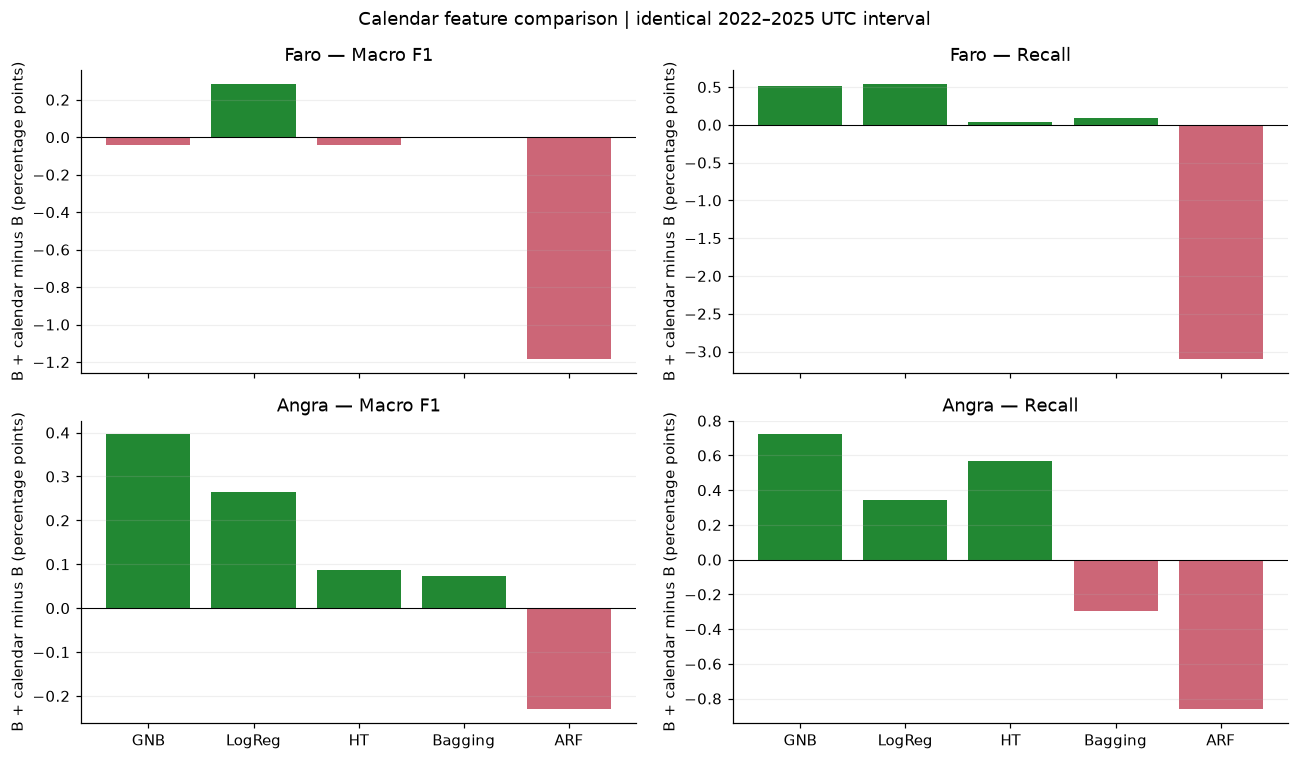

In [5]:
show_scores(tables["calendar_metrics"])
deltas = tables["calendar_deltas"]
display(deltas[["city", "model", "n_events", "rain_hours", "dry_hours"] + ["delta_" + metric for metric in SCORES]].round(5))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, city in enumerate(CITIES):
    part = deltas.query("city == @city").set_index("model").reindex(MODELS)
    for col, metric in enumerate(["macro_f1", "recall"]):
        ax = axes[row, col]
        values = part["delta_" + metric] * 100
        ax.bar(SHORT, values, color=["#228833" if x >= 0 else "#CC6677" for x in values])
        ax.axhline(0, color="black", lw=0.7)
        ax.set(title=f"{city} — {metric.replace('_', ' ').title()}", ylabel="B + calendar minus B (percentage points)")
        ax.grid(axis="y", alpha=0.2)
fig.suptitle("Calendar feature comparison | identical 2022–2025 UTC interval")
fig.tight_layout()
save_figure(fig, "calendar_differences")

### Monthly baseline context

The B baseline is displayed by UTC calendar month, with individual years visible
and rainy-hour counts alongside metrics. Monthly exports retain **all 2021–2025**
eligible hours; the plots select 2022–2025 to match the calendar diagnostic.
Undefined rain recall and single-class Macro-F1 are shown as gaps, never as
invented zeros. A low value in a month is not sufficient to attribute errors to
seasonality, and a learned model does not forget its state after 24 hours.

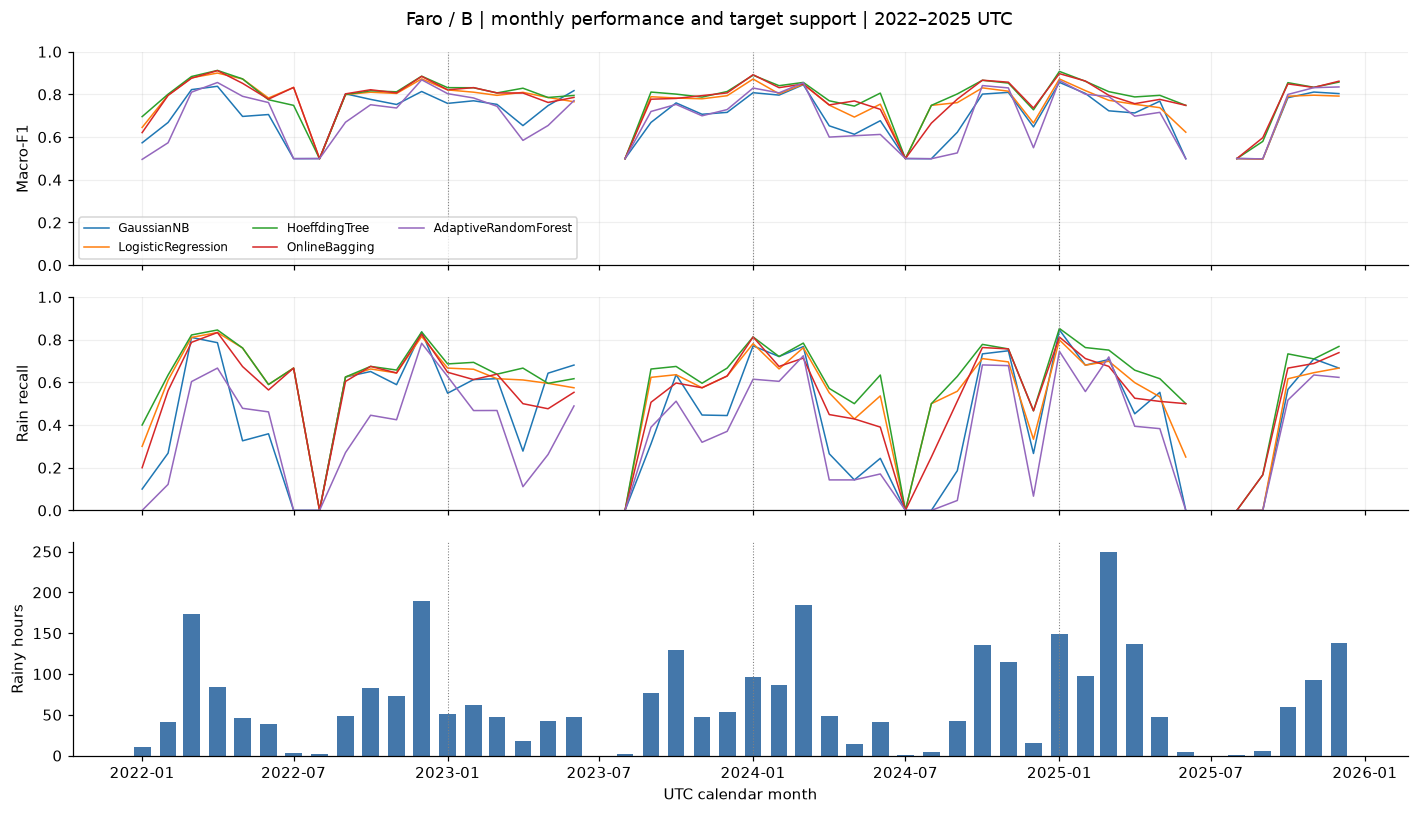

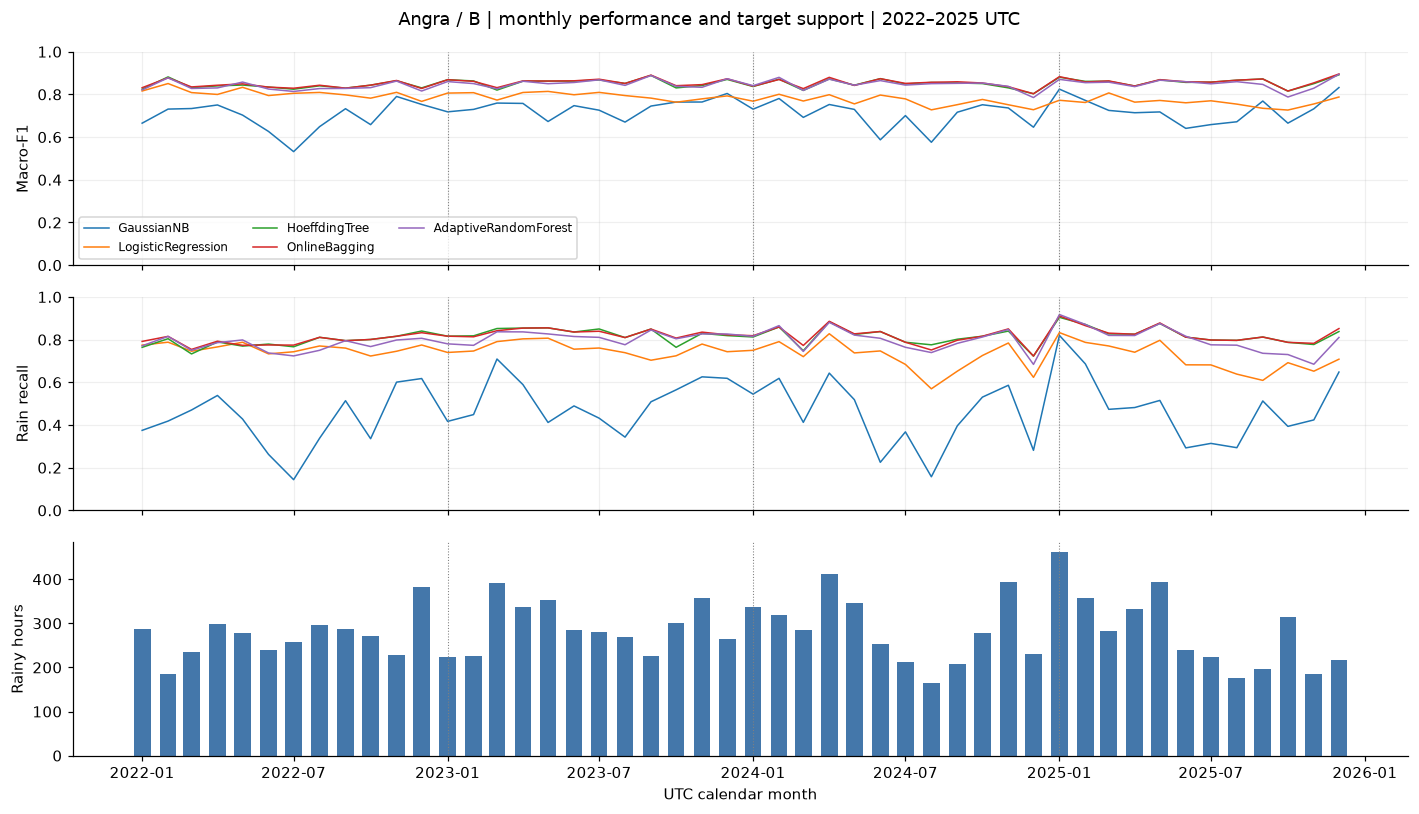

In [6]:
baseline = tables["monthly_baseline_metrics"]
for city in CITIES:
    part = baseline.query("city == @city and year >= 2022")
    fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
    for ax, metric, label in zip(axes[:2], ["macro_f1_display", "recall_display"], ["Macro-F1", "Rain recall"]):
        for name in MODELS:
            selected = part.query("model == @name")
            ax.plot(pd.to_datetime(selected.period), selected[metric], label=name, color=COLORS[name], lw=1)
        ax.set(ylabel=label, ylim=(0, 1))
        ax.grid(alpha=0.2)
    counts = part.loc[part.model.eq(MODELS[0])]
    axes[2].bar(pd.to_datetime(counts.period), counts.rain_hours, width=20, color="#4477AA")
    axes[2].set(ylabel="Rainy hours", xlabel="UTC calendar month")
    axes[0].legend(ncol=3, fontsize=8)
    for ax in axes:
        for year in [2023, 2024, 2025]:
            ax.axvline(pd.Timestamp(f"{year}-01-01"), color="gray", ls=":", lw=0.7)
    fig.suptitle(f"{city} / B | monthly performance and target support | 2022–2025 UTC")
    fig.tight_layout()
    save_figure(fig, f"monthly_B_{city}")

## 3. Rain transitions: where do errors occur?

Observed T1 values classify every hour using its **real preceding hour** before
filtering the diagnostic interval, including the 2021→2022 boundary. These labels
are used only after prediction for diagnosis; they are not extra model inputs.

| Situation | Previous hour | Predicted hour | Conditional rate |
|---|---|---|---|
| Rain onset | Dry | Rain | Detection = TP / (TP + FN) |
| Continued rain | Rain | Rain | Detection = TP / (TP + FN) |
| Rain cessation | Rain | Dry | False alarm = FP / (TN + FP) |
| Continued dry weather | Dry | Dry | False alarm = FP / (TN + FP) |

Each denominator is the number of hours in that situation. Supports match
across A, B and B + calendar for every model. Higher detection and lower false
alarm are preferable. A missing denominator gives NaN and a plotting gap.
Precision and Macro-F1 are not computed inside these constant-target groups.

,city,transition,n_events,city_hours,frequency
0,Faro,Rain onset,861,35064,0.0246
1,Faro,Continued rain,2272,35064,0.0648
2,Faro,Rain cessation,861,35064,0.0246
3,Faro,Continued dry weather,31070,35064,0.8861
4,Angra,Rain onset,2347,35064,0.0669
5,Angra,Continued rain,11230,35064,0.3203
6,Angra,Rain cessation,2348,35064,0.0670
7,Angra,Continued dry weather,19139,35064,0.5458


,city,representation,model,transition,n_events,tp,fn,tn,fp,detection_rate,false_alarm_rate
20,Faro,B,GaussianNB,Rain onset,861,195,666,0,0,0.2265,NaN
21,Faro,B,GaussianNB,Continued rain,2272,1796,476,0,0,0.7905,NaN
22,Faro,B,GaussianNB,Rain cessation,861,0,0,406,455,NaN,0.5285
23,Faro,B,GaussianNB,Continued dry weather,31070,0,0,30308,762,NaN,0.0245
24,Faro,B,LogisticRegression,Rain onset,861,18,843,0,0,0.0209,NaN
25,Faro,B,LogisticRegression,Continued rain,2272,2116,156,0,0,0.9313,NaN
26,Faro,B,LogisticRegression,Rain cessation,861,0,0,54,807,NaN,0.9373
27,Faro,B,LogisticRegression,Continued dry weather,31070,0,0,30870,200,NaN,0.0064
28,Faro,B,HoeffdingTree,Rain onset,861,0,861,0,0,0.0000,NaN
29,Faro,B,HoeffdingTree,Continued rain,2272,2272,0,0,0,1.0000,NaN


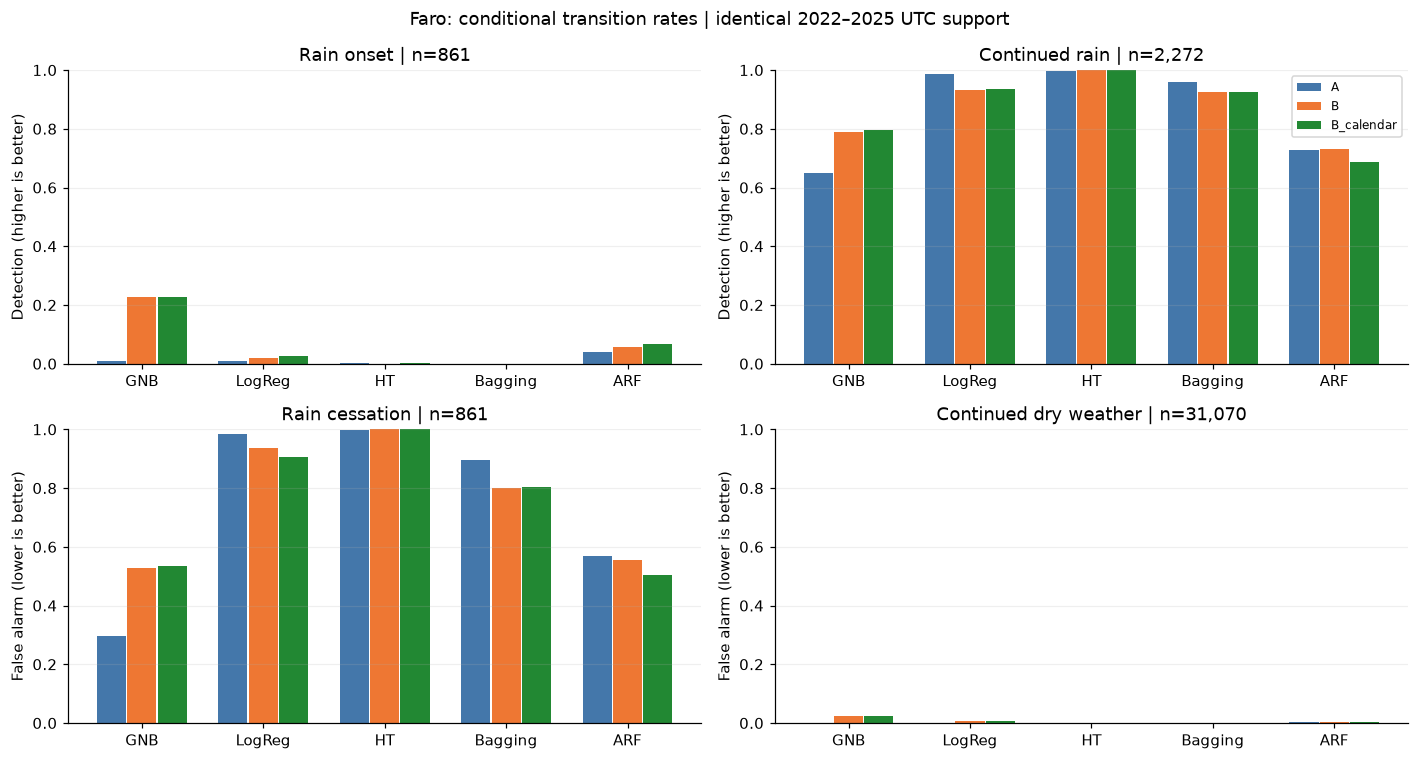

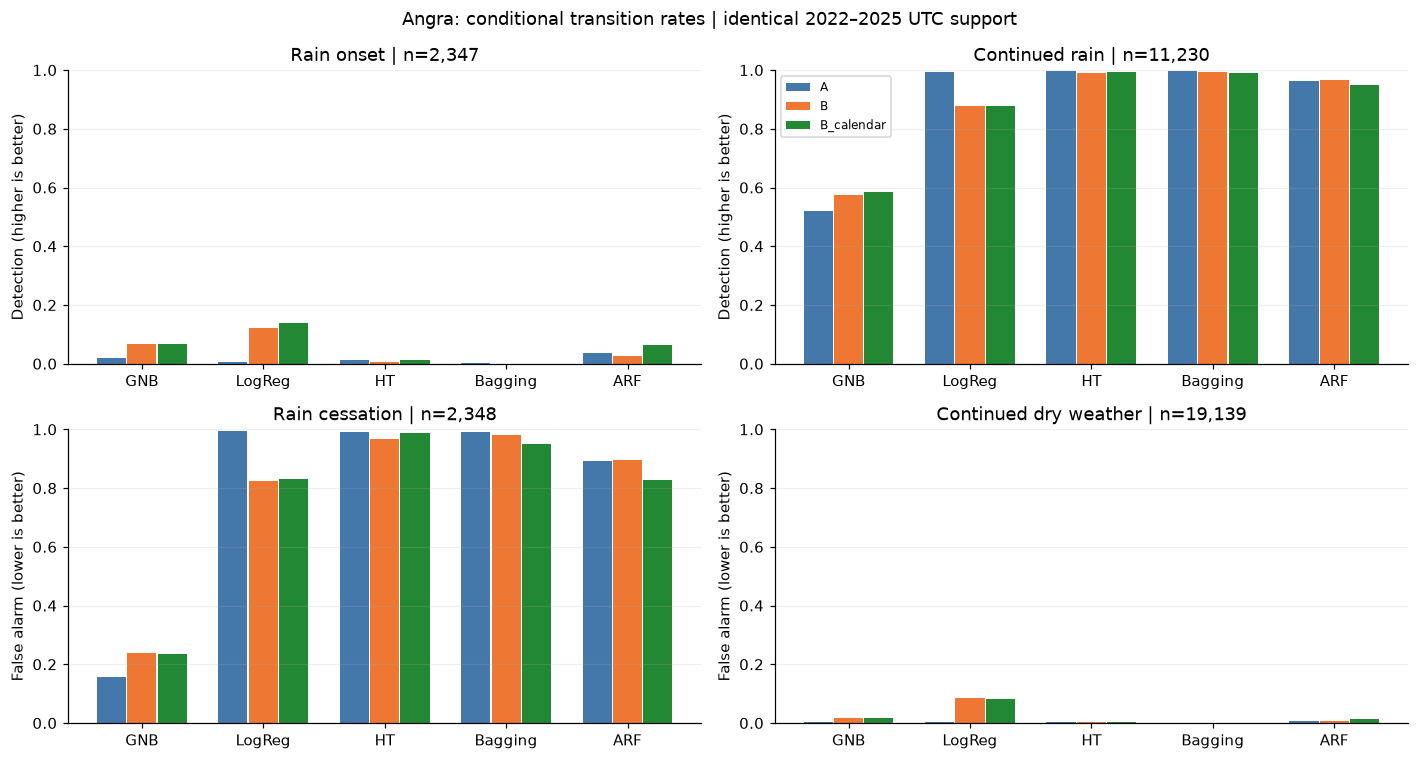

In [7]:
display(tables["transition_frequency"].round(4))
transitions = tables["transition_metrics"]
display(transitions.loc[transitions.representation.eq("B"),
    GROUPS + ["transition", "n_events", "tp", "fn", "tn", "fp", "detection_rate", "false_alarm_rate"]].round(4))
for city in CITIES:
    fig, axes = plt.subplots(2, 2, figsize=(13, 7))
    for ax, (situation, (_, actual)) in zip(axes.flat, TRANSITIONS.items()):
        metric = "detection_rate" if actual else "false_alarm_rate"
        for offset, rep, color in [(-0.25, "A", "#4477AA"), (0, "B", "#EE7733"), (0.25, "B_calendar", "#228833")]:
            selected = transitions.query("city == @city and transition == @situation and representation == @rep").set_index("model").reindex(MODELS)
            ax.bar(np.arange(5) + offset, selected[metric], width=0.24, label=rep, color=color)
        n = int(selected.n_events.iloc[0])
        ax.set(title=f"{situation} | n={n:,}", ylim=(0, 1), xticks=np.arange(5),
               xticklabels=SHORT, ylabel="Detection (higher is better)" if actual else "False alarm (lower is better)")
        ax.grid(axis="y", alpha=0.2)
    axes[0, 1].legend(fontsize=8)
    fig.suptitle(f"{city}: conditional transition rates | identical 2022–2025 UTC support")
    fig.tight_layout()
    save_figure(fig, f"transitions_{city}")

### Contributions to total errors and monthly diagnostics

`error_share_within_type` answers a different question: what fraction of **all
false negatives** comes from onset/continued rain, or what fraction of **all false
positives** comes from cessation/continued dry weather? Its denominator is the
parent interval's total FN or FP, not the situation's number of hours. Read error
shares together with conditional rates and supports, since frequent situations
can contribute many errors despite a small conditional error rate.

The complete monthly counts and conditional rates are retained in
`monthly_transition_metrics.csv`; this condensed notebook avoids repeating all
30 time-series panels.

In [8]:
display(transitions[GROUPS + ["transition", "n_events", "error_type", "n_errors", "error_type_total", "error_share_within_type"]].round(4))

,city,representation,model,transition,n_events,error_type,n_errors,error_type_total,error_share_within_type
0,Faro,A,GaussianNB,Rain onset,861,FN,853,1649,0.5173
1,Faro,A,GaussianNB,Continued rain,2272,FN,796,1649,0.4827
2,Faro,A,GaussianNB,Rain cessation,861,FP,256,260,0.9846
3,Faro,A,GaussianNB,Continued dry weather,31070,FP,4,260,0.0154
4,Faro,A,LogisticRegression,Rain onset,861,FN,854,885,0.9650
5,Faro,A,LogisticRegression,Continued rain,2272,FN,31,885,0.0350
6,Faro,A,LogisticRegression,Rain cessation,861,FP,847,871,0.9724
7,Faro,A,LogisticRegression,Continued dry weather,31070,FP,24,871,0.0276
8,Faro,A,HoeffdingTree,Rain onset,861,FN,858,862,0.9954
9,Faro,A,HoeffdingTree,Continued rain,2272,FN,4,862,0.0046


## Conclusion

Aggregate warm-up differences were generally small, although the candidates
score different historical periods and therefore do not isolate an initial
learning effect. The final evaluation retains the 30-day protocol. On the common
2022–2025 diagnostic interval, calendar features produced mixed, model-dependent
changes rather than a consistent improvement. Rain onset was much harder to
detect than continued rain, while false alarms were more frequent at rain
cessation than during continued dry weather. These contrasts locate transition
errors without establishing their cause. Monthly variation alone does not show
that seasonal changes cause failures, and neither calendar additions nor a
longer scoring warm-up resolves all observed difficulties.